[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/notebooks/11_final_project.ipynb)

<div dir="rtl">

# جلسه ۱۱: پروژه‌ی پایانی، تحلیل سفرهای تاکسی نیویورک

**اهداف این جلسه**

- اجرای یک پروژه‌ی کامل علم داده از سؤال تا گزارش
- ترکیب همه‌ی ابزارهای ترم: NumPy، Pandas، SQL، نمودار، احتمال و آمار
- پیدا کردن یک **سوگیری در شیوه‌ی ثبت داده** که می‌تواند کل تحلیل را خراب کند
- نوشتن یافته‌ها برای یک مخاطب غیرفنی
- آشنایی با معیارهای ارزیابی پروژه‌ی پایانی دانشجویان

این نوت‌بوک یک **نمونه‌ی کامل** است؛ پروژه‌ی پایانی شما باید همین ساختار را روی یک داده‌ی دیگر داشته باشد (بخش آخر).

</div>

<div dir="rtl">

## ۱. سؤال‌ها

یک شرکت حمل‌ونقل می‌خواهد قبل از ورود به بازار، الگوی سفرهای تاکسی در نیویورک را بشناسد. سؤال‌های ما:

1. سفرها در چه **زمان‌هایی** از روز و هفته متمرکزند؟
2. کرایه چه رابطه‌ای با **مسافت** و **مدت** سفر دارد؟
3. مسافران چقدر **انعام** می‌دهند و انعام به چه چیزی بستگی دارد؟
4. آیا درصد انعام در تاکسی‌های **زرد** و **سبز** متفاوت است؟

**داده:** نمونه‌ای از ۶۴۳۳ سفر تاکسی در نیویورک در مارس ۲۰۱۹ (کرایه‌ها به دلار، مسافت به مایل).

</div>

In [1]:
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"

raw = pd.read_csv(DATA_URL + "taxis.csv", parse_dates=["pickup", "dropoff"])
print(raw.shape)
raw.head()

(6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


<div dir="rtl">

## ۲. شناخت و پاک‌سازی داده

</div>

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [3]:
raw.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
pickup,6433,2019-03-16 08:31:28.514223,2019-02-28 23:29:03,2019-03-08 15:50:34,2019-03-15 21:46:58,2019-03-23 17:41:38,2019-03-31 23:43:45,NaN
dropoff,6433,2019-03-16 08:45:49.491216,2019-02-28 23:32:35,2019-03-08 16:12:51,2019-03-15 22:06:44,2019-03-23 17:51:56,2019-04-01 00:13:58,NaN
passengers,6433.0,1.539251,0.0,1.0,1.0,2.0,6.0,1.203768
distance,6433.0,3.024617,0.0,0.98,1.64,3.21,36.7,3.827867
fare,6433.0,13.091073,1.0,6.5,9.5,15.0,150.0,11.551804
tip,6433.0,1.97922,0.0,0.0,1.7,2.8,33.2,2.44856
tolls,6433.0,0.325273,0.0,0.0,0.0,0.0,24.02,1.415267
total,6433.0,18.517794,1.3,10.8,14.16,20.3,174.82,13.81557


In [4]:
df = raw.copy()
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60

checks = pd.Series({
    "duplicate rows": df.duplicated().sum(),
    "duration <= 0 min": (df["duration_min"] <= 0).sum(),
    "distance == 0": (df["distance"] == 0).sum(),
    "passengers == 0": (df["passengers"] == 0).sum(),
    "missing payment": df["payment"].isna().sum(),
    "missing pickup zone": df["pickup_zone"].isna().sum(),
    "pickup outside March 2019": (df["pickup"] < "2019-03-01").sum(),
})
checks

duplicate rows                0
duration <= 0 min             6
distance == 0                51
passengers == 0              96
missing payment              44
missing pickup zone          26
pickup outside March 2019     1
dtype: int64

<div dir="rtl">

تصمیم‌های پاک‌سازی (هر تصمیم را مستند می‌کنیم):

- سفرهای با مدت صفر یا منفی و مسافت صفر: احتمالاً لغو شده یا خطای دستگاه؛ **حذف**.
- سفرهای خارج از مارس ۲۰۱۹: خارج از دامنه‌ی مطالعه؛ **حذف**.
- `passengers == 0`: خطای ثبت راننده است، اما کرایه و انعام آن سفر معتبر است؛ **نگه می‌داریم** و در تحلیل تعداد مسافر کنار می‌گذاریم.
- روش پرداخت و منطقه‌ی گمشده: تعدادشان کم است؛ فقط در تحلیل‌هایی که به آن ستون نیاز دارند کنار گذاشته می‌شوند.

</div>

In [5]:
df = df[(df["duration_min"] > 0) & (df["distance"] > 0) & (df["pickup"] >= "2019-03-01")].copy()
df["hour"] = df["pickup"].dt.hour
df["weekday"] = pd.Categorical(df["pickup"].dt.day_name(),
                               categories=["Monday", "Tuesday", "Wednesday", "Thursday",
                                           "Friday", "Saturday", "Sunday"], ordered=True)
df["speed_mph"] = df["distance"] / (df["duration_min"] / 60)
df["tip_pct"] = df["tip"] / df["fare"] * 100
print(f"kept {len(df)} of {len(raw)} trips ({len(df) / len(raw):.1%})")

kept 6381 of 6433 trips (99.2%)


In [6]:
df["speed_mph"].describe(percentiles=[0.01, 0.5, 0.99]).round(1)

count    6381.0
mean       13.2
std        68.3
min         1.2
1%          3.5
50%        10.1
99%        34.0
max      4834.3
Name: speed_mph, dtype: float64

<div dir="rtl">

سرعت بیشینه بسیار بالاست که با ترافیک نیویورک سازگار نیست. سفرهای با سرعت بیش از ۶۰ مایل بر ساعت را غیرمعتبر در نظر می‌گیریم:

</div>

In [7]:
print("trips faster than 60 mph:", (df["speed_mph"] > 60).sum())
df = df[df["speed_mph"] <= 60].copy()
assert (df["duration_min"] > 0).all() and (df["distance"] > 0).all()
print(df.shape)

trips faster than 60 mph: 11
(6370, 19)


<div dir="rtl">

## ۳. سؤال ۱: الگوی زمانی سفرها

</div>

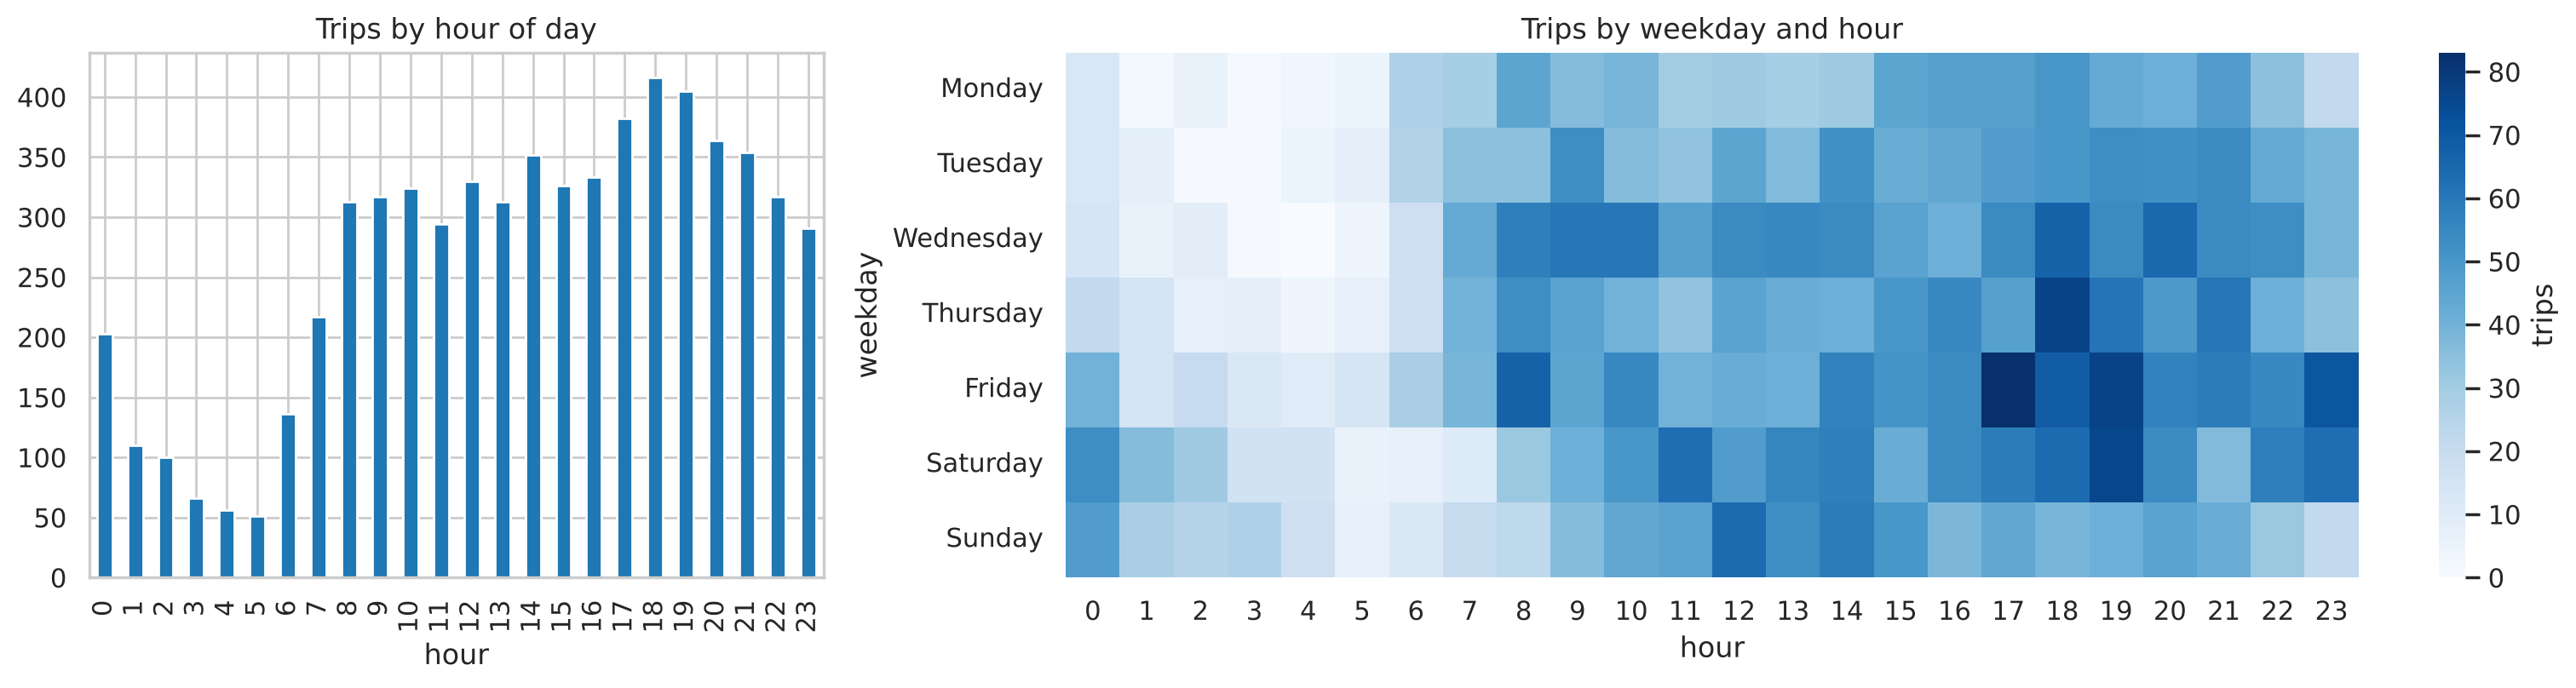

In [8]:
heat = df.pivot_table(index="weekday", columns="hour", values="fare", aggfunc="count", observed=False).fillna(0)
weeks = df["pickup"].dt.isocalendar().week.nunique()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
df["hour"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="tab:blue")
axes[0].set_title("Trips by hour of day")
axes[0].set_xlabel("hour")
sns.heatmap(heat, cmap="Blues", ax=axes[1], cbar_kws={"label": "trips"})
axes[1].set_title("Trips by weekday and hour")
plt.tight_layout()
plt.show()

<div dir="rtl">

- اوج سفرها عصرها (حدود ساعت ۱۸ تا ۱۹) است و کمترین سفر حدود ساعت ۴ تا ۵ صبح.
- در روزهای کاری، یک اوج صبحگاهی (رفتن به کار) هم دیده می‌شود؛ در آخر هفته اوج صبحگاهی وجود ندارد و در عوض سفرهای بامداد شنبه و یکشنبه (شب‌های تفریح) بیشتر است.

## ۴. سؤال ۲: کرایه، مسافت و مدت

برای تمرین SQL، این بخش را با یک پایگاه داده‌ی درون حافظه انجام می‌دهیم:

</div>

In [9]:
conn = sqlite3.connect(":memory:")
df.drop(columns=["weekday"]).assign(weekday=df["weekday"].astype(str)).to_sql("trips", conn, index=False)

pd.read_sql_query("""
SELECT pickup_borough AS borough,
       COUNT(*)                      AS trips,
       ROUND(AVG(distance), 2)       AS avg_miles,
       ROUND(AVG(duration_min), 1)   AS avg_minutes,
       ROUND(AVG(fare), 2)           AS avg_fare,
       ROUND(AVG(fare / distance), 2) AS fare_per_mile
FROM trips
WHERE pickup_borough IS NOT NULL
GROUP BY pickup_borough
ORDER BY trips DESC
""", conn)

,borough,trips,avg_miles,avg_minutes,avg_fare,fare_per_mile
0,Manhattan,5248,2.36,12.8,11.14,6.26
1,Queens,636,7.67,23.6,25.31,5.46
2,Brooklyn,374,4.16,19.4,16.46,5.39
3,Bronx,97,5.84,24.4,20.67,5.35


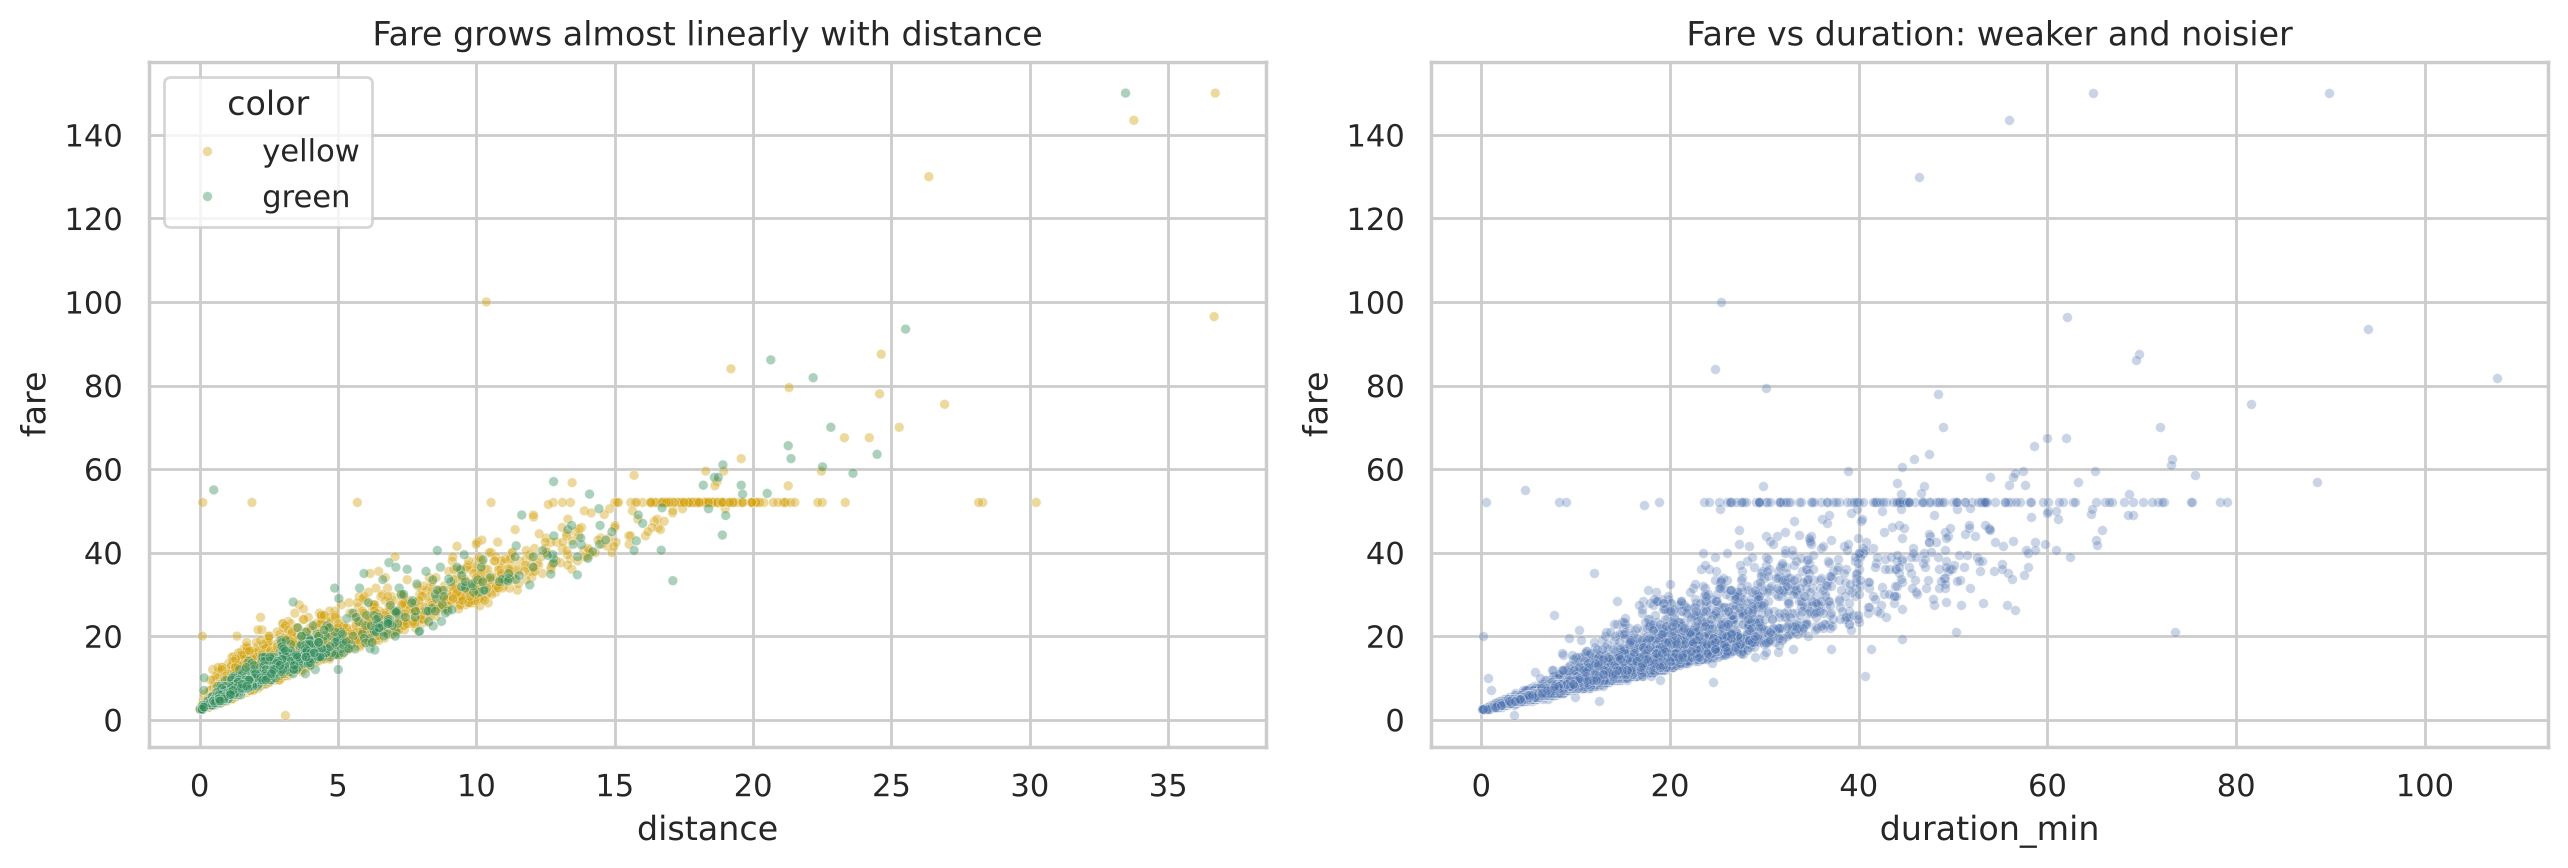

corr(fare, distance)     = 0.959
corr(fare, duration_min) = 0.887


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="distance", y="fare", hue="color", alpha=0.4, s=12, ax=axes[0],
                palette={"yellow": "#d4a20b", "green": "#2e8b57"})
axes[0].set_title("Fare grows almost linearly with distance")
sns.scatterplot(data=df, x="duration_min", y="fare", alpha=0.3, s=12, ax=axes[1])
axes[1].set_title("Fare vs duration: weaker and noisier")
plt.tight_layout()
plt.show()

print("corr(fare, distance)     =", round(df["fare"].corr(df["distance"]), 3))
print("corr(fare, duration_min) =", round(df["fare"].corr(df["duration_min"]), 3))

In [11]:
X = np.column_stack([np.ones(len(df)), df["distance"], df["duration_min"]])
beta, *_ = np.linalg.lstsq(X, df["fare"].values, rcond=None)
pred = X @ beta
r2 = 1 - ((df["fare"] - pred) ** 2).sum() / ((df["fare"] - df["fare"].mean()) ** 2).sum()
print(f"fare ≈ {beta[0]:.2f} + {beta[1]:.2f} * miles + {beta[2]:.2f} * minutes   (R^2 = {r2:.3f})")

fare ≈ 2.45 + 2.08 * miles + 0.29 * minutes   (R^2 = 0.949)


<div dir="rtl">

با کمترین مربعات (جلسه‌ی ۱۰)، کرایه تقریباً برابر است با یک مبلغ پایه‌ی حدود ۲٫۵ دلار، به‌علاوه‌ی حدود ۲ دلار برای هر مایل و حدود ۰٫۳ دلار برای هر دقیقه. این دو متغیر با هم حدود ۹۵٪ تغییرات کرایه را توضیح می‌دهند؛ که با ساختار واقعی تعرفه‌ی تاکسی (ورودی + مسافت + زمان در ترافیک) سازگار است.

## ۵. سؤال ۳: انعام، و یک دام بزرگ

میانگین درصد انعام به تفکیک روش پرداخت:

</div>

In [12]:
df.groupby("payment")["tip_pct"].agg(["count", "mean", lambda s: (s > 0).mean()]).rename(
    columns={"<lambda_0>": "share_with_tip"}).round(2)

,count,mean,share_with_tip
payment,,,
cash,1787,0.00,0.0
credit card,4549,23.87,0.9


<div dir="rtl">

**هیچ** سفر نقدی انعام ندارد. آیا مسافرانی که نقد پرداخت می‌کنند هیچ‌وقت انعام نمی‌دهند؟ تقریباً مطمئناً نه. توضیح واقعی، **شیوه‌ی ثبت داده** است: انعام کارتی به‌طور خودکار ثبت می‌شود، اما انعام نقدی مستقیم به جیب راننده می‌رود و در سیستم ثبت نمی‌شود.

اگر این را نمی‌دیدیم و میانگین انعام کل داده را گزارش می‌کردیم، عدد را به‌طور سیستماتیک **کمتر** از واقعیت گزارش کرده بودیم. همچنین هر مقایسه‌ای (مثلاً بین مناطق) که در آن سهم پرداخت نقدی متفاوت است، مخدوش می‌شد.

**تصمیم:** تحلیل انعام را **فقط روی سفرهای کارتی** انجام می‌دهیم و این محدودیت را صریحاً در گزارش می‌نویسیم.

</div>

card trips: 4549
median tip on card trips: 25.6% of the fare


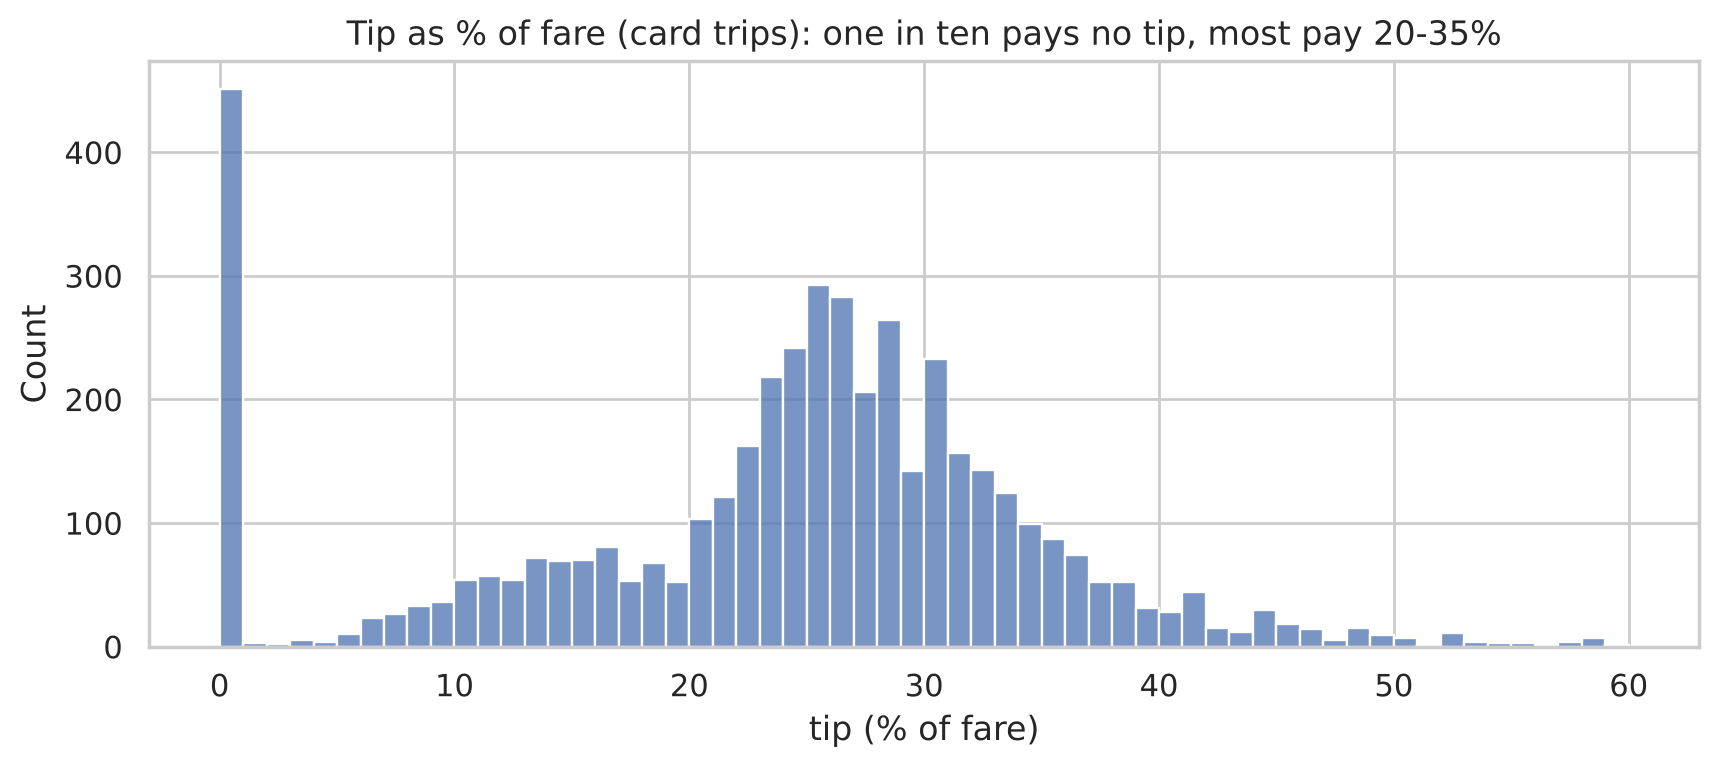

In [13]:
card = df[df["payment"] == "credit card"].copy()
print(f"card trips: {len(card)}")
print(f"median tip on card trips: {card['tip_pct'].median():.1f}% of the fare")

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.histplot(card.loc[card["tip_pct"] <= 60, "tip_pct"], binwidth=1, ax=ax)
ax.set_title("Tip as % of fare (card trips): one in ten pays no tip, most pay 20-35%")
ax.set_xlabel("tip (% of fare)")
plt.show()

<div dir="rtl">

دو چیز در این نمودار دیده می‌شود:

- حدود یک‌دهم سفرهای کارتی **بدون انعام** هستند (ستون صفر).
- بیشتر انعام‌ها بین ۲۰ تا ۳۵ درصد کرایه و متمرکز حول ۲۵٪ است. صفحه‌ی پرداخت تاکسی‌های نیویورک دکمه‌های پیشنهادی ۲۰، ۲۵ و ۳۰ درصد دارد و این تمرکز احتمالاً اثر همین **پیش‌فرض‌ها**ست. چون آن درصدها روی مبلغ کل (کرایه به‌علاوه‌ی هزینه‌های جانبی) حساب می‌شوند، وقتی انعام را نسبت به کرایه می‌سنجیم، قله‌ها پخش و کمی جابه‌جا می‌شوند.

## ۶. سؤال ۴: تاکسی زرد یا سبز؟

تاکسی‌های زرد بیشتر در مرکز منهتن و تاکسی‌های سبز در محله‌های بیرونی کار می‌کنند. آیا درصد انعام کارتی آن‌ها متفاوت است؟

</div>

In [14]:
rng = np.random.default_rng(1405)
yellow = card.loc[card["color"] == "yellow", "tip_pct"].values
green = card.loc[card["color"] == "green", "tip_pct"].values
print(f"yellow: n={len(yellow)}, mean={yellow.mean():.2f}%, median={np.median(yellow):.2f}%")
print(f"green : n={len(green)}, mean={green.mean():.2f}%, median={np.median(green):.2f}%")

t = stats.ttest_ind(yellow, green, equal_var=False)
u = stats.mannwhitneyu(yellow, green)
boot = np.array([rng.choice(yellow, len(yellow)).mean() - rng.choice(green, len(green)).mean()
                 for _ in range(5000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
pooled_sd = np.sqrt((yellow.var(ddof=1) + green.var(ddof=1)) / 2)

print(f"\ndifference (yellow - green) = {yellow.mean() - green.mean():.2f} points, 95% bootstrap CI [{lo:.2f}, {hi:.2f}]")
print(f"Cohen's d ≈ {(yellow.mean() - green.mean()) / pooled_sd:.2f}")
print(f"Welch t-test  : p = {t.pvalue:.1e}")
print(f"Mann-Whitney U: p = {u.pvalue:.1e}   (rank-based, robust to the skew and spikes)")

yellow: n=3984, mean=25.42%, median=26.33%
green : n=565, mean=12.93%, median=11.76%



difference (yellow - green) = 12.49 points, 95% bootstrap CI [11.31, 13.58]
Cohen's d ≈ 1.04
Welch t-test  : p = 1.8e-76
Mann-Whitney U: p = 8.8e-94   (rank-based, robust to the skew and spikes)


<div dir="rtl">

اختلاف از نظر آماری معنی‌دار است و کل بازه‌ی اطمینان بالای صفر قرار دارد. چون توزیع انعام قله‌دار و چوله است، علاوه بر آزمون t، آزمون **من-ویتنی** (مبتنی بر رتبه) را هم انجام دادیم که به شکل توزیع حساس نیست و همان نتیجه را می‌دهد.

**اما احتیاط:** این یک مطالعه‌ی **مشاهده‌ای** است، نه آزمایش تصادفی‌شده. رنگ تاکسی با منطقه، نوع مسافر و طول سفر همبسته است. پس می‌توانیم بگوییم «مسافران تاکسی زرد به‌طور میانگین درصد بیشتری انعام می‌دهند»، اما **نمی‌توانیم** بگوییم «رنگ تاکسی باعث انعام بیشتر می‌شود».

یک بررسی برای متغیر مخدوش‌کننده: آیا اختلاف داخل خود منهتن هم باقی می‌ماند؟

</div>

In [15]:
(card.groupby(["pickup_borough", "color"])["tip_pct"]
     .agg(["count", "median"])
     .query("count >= 20")
     .round(1))

count  median
pickup_borough color                
Bronx          green      61     0.0
Brooklyn       green     212     0.0
               yellow     45    21.0
Manhattan      green     155    22.3
               yellow   3678    26.7
Queens         green     137    11.8
               yellow    238    21.8

<div dir="rtl">

- داخل **منهتن**، اختلاف میانه‌ی دو رنگ از حدود ۱۴ واحد (کل داده) به حدود ۴ واحد کاهش می‌یابد. پس بخش بزرگی از اختلاف کلی، اثر **منطقه** است: تاکسی‌های سبز بیشتر در محله‌هایی کار می‌کنند که انعام در آن‌ها کمتر است.
- در بروکلین و برانکس، میانه‌ی انعام کارتی تاکسی‌های سبز **صفر** است؛ یعنی بیش از نیمی از این مسافران انعام نمی‌دهند. این یافته ارزش بررسی جداگانه دارد.

</div>

<div dir="rtl">

## ۷. گزارش نهایی برای مدیر

**خلاصه**

1. **زمان:** بیشترین تقاضا در عصرهای روزهای کاری (حدود ساعت ۱۸ تا ۱۹) است. آخر هفته‌ها الگوی متفاوتی دارند: بدون اوج صبحگاهی و با سفرهای شبانه‌ی بیشتر.
2. **کرایه:** تقریباً با یک فرمول ساده‌ی «ورودی + مسافت + زمان» قابل پیش‌بینی است (حدود ۹۵٪ تغییرات).
3. **انعام:** در سفرهای کارتی، میانه‌ی انعام حدود یک‌چهارم کرایه است و حدود یک‌دهم مسافران انعام نمی‌دهند. تمرکز انعام‌ها حول دکمه‌های پیشنهادی نشان می‌دهد **طراحی صفحه‌ی پرداخت** احتمالاً روی درآمد رانندگان اثر دارد.
4. **زرد و سبز:** مسافران تاکسی زرد به‌طور میانگین حدود ۱۲ واحد درصد بیشتر انعام می‌دهند، اما بیشتر این تفاوت به **منطقه** برمی‌گردد: داخل منهتن، اختلاف به حدود ۴ واحد کاهش می‌یابد.

**محدودیت‌ها**

- انعام نقدی ثبت نمی‌شود؛ همه‌ی نتایج انعام فقط مربوط به پرداخت کارتی است.
- داده فقط یک ماه (مارس ۲۰۱۹) را پوشش می‌دهد؛ فصل و سال‌های دیگر ممکن است متفاوت باشند.
- داده نمونه‌ای کوچک از کل سفرهاست.
- نتایج مشاهده‌ای‌اند و ادعای علّی نمی‌کنند.

**پیشنهاد برای قدم بعد:** یک آزمون A/B روی دکمه‌های پیش‌فرض صفحه‌ی پرداخت، تا اثر علّی آن‌ها بر انعام اندازه‌گیری شود.

</div>

In [16]:
conn.close()

<div dir="rtl">

## ۸. پروژه‌ی پایانی دانشجویان

یک مجموعه‌داده‌ی واقعی انتخاب کنید (پیشنهادها در ادامه) و یک تحلیل کامل با ساختار همین نوت‌بوک انجام دهید.

**ساختار لازم**

1. **سؤال‌ها:** حداقل سه سؤال مشخص و قابل‌پاسخ با داده
2. **پاک‌سازی:** مستندسازی هر تصمیم و دلیل آن، و بررسی‌های `assert`
3. **EDA:** حداقل شش نمودار مناسب با عنوان‌هایی که پیام را می‌گویند
4. **SQL:** حداقل دو پرسش، شامل یک `JOIN` یا تابع پنجره‌ای
5. **آمار:** حداقل یک آزمون فرض همراه با بازه‌ی اطمینان و اندازه‌ی اثر
6. **گزارش:** یافته‌ها، محدودیت‌ها و پیشنهاد، به زبان ساده و حداکثر در یک صفحه
7. **ارائه:** ۱۰ دقیقه ارائه در کلاس

**معیار ارزیابی**

| بخش | سهم از نمره |
|---|---|
| کیفیت سؤال‌ها و ارتباط تحلیل با آن‌ها | ۱۵٪ |
| پاک‌سازی و مستندسازی | ۲۰٪ |
| تحلیل اکتشافی و کیفیت نمودارها | ۲۰٪ |
| SQL | ۱۰٪ |
| استدلال آماری درست (و پرهیز از ادعای علّی بی‌پشتوانه) | ۲۰٪ |
| گزارش و ارائه | ۱۵٪ |

**پیشنهاد داده**

- داده‌ی فروشگاه اینترنتی همین دوره (`orders_raw.csv`، `customers.csv`، `products.csv`): از داده‌ی خام شروع کنید.
- داده‌های عمومی [Kaggle](https://www.kaggle.com/datasets) یا [داده‌های باز دولتی](https://data.gov)
- داده‌ی کار یا محیط خودتان (با رعایت محرمانگی و حذف اطلاعات شخصی)

</div>